First rows:
      City      Date    AQI  PM2.5    PM10     NO2     SO2    CO      O3
0  Chennai  01/01/18   93.0  51.15  100.44   77.19  106.02  0.98   88.35
1  Chennai  02/01/18  100.0  55.00  108.00   83.00  114.00  1.05   95.00
2  Chennai  03/01/18   81.0  44.55   87.48   67.23   92.34  0.85   76.95
3  Chennai  04/01/18  169.0  92.95  182.52  140.27  192.66  1.77  160.55
4  Chennai  05/01/18  153.0  84.15  165.24  126.99  174.42  1.61  145.35

Columns:
['City', 'Date', 'AQI', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3']

Missing values:
City     0
Date     0
AQI      1
PM2.5    0
PM10     0
NO2      0
SO2      0
CO       0
O3       0
dtype: int64


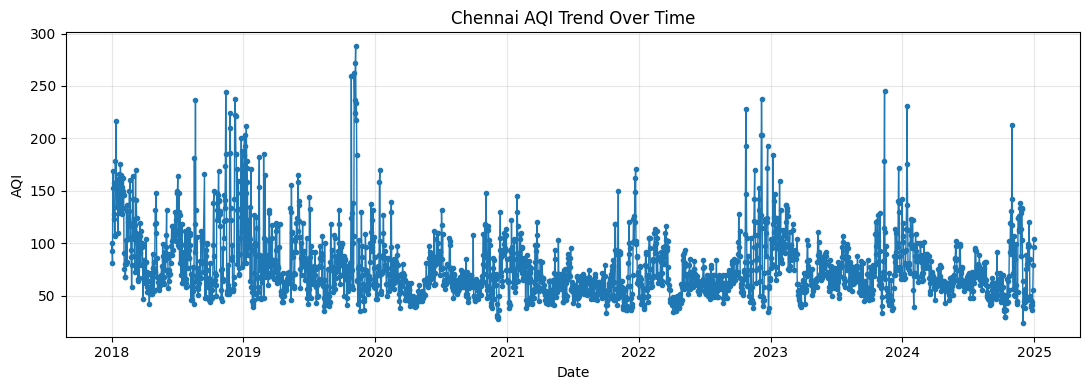

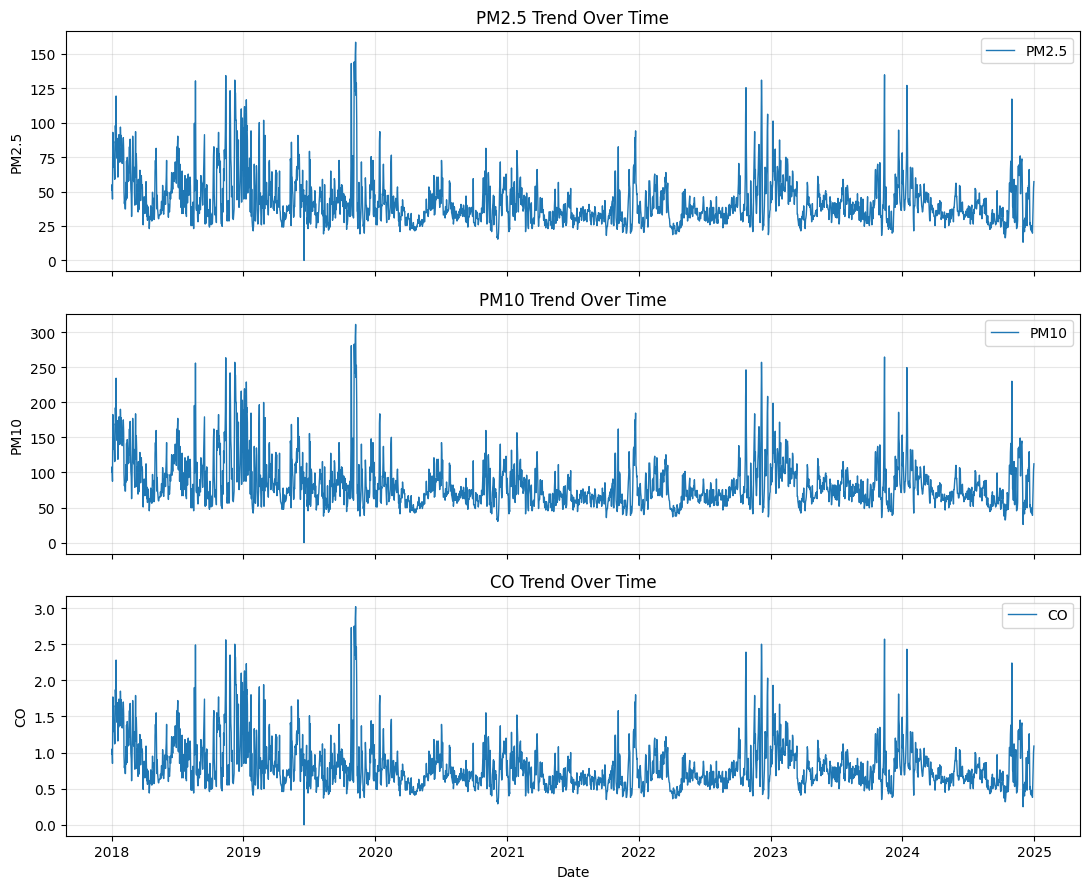

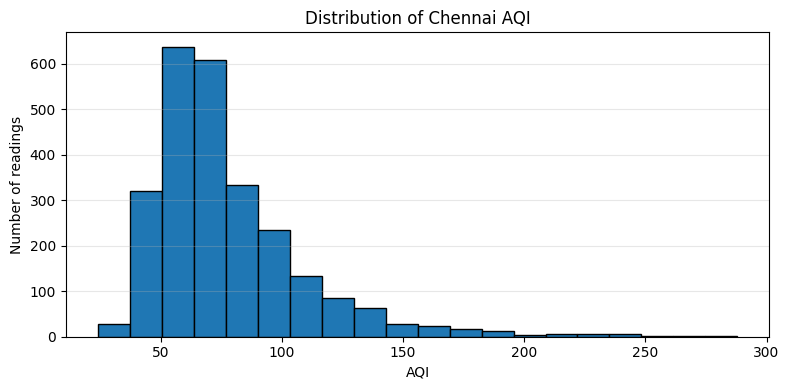

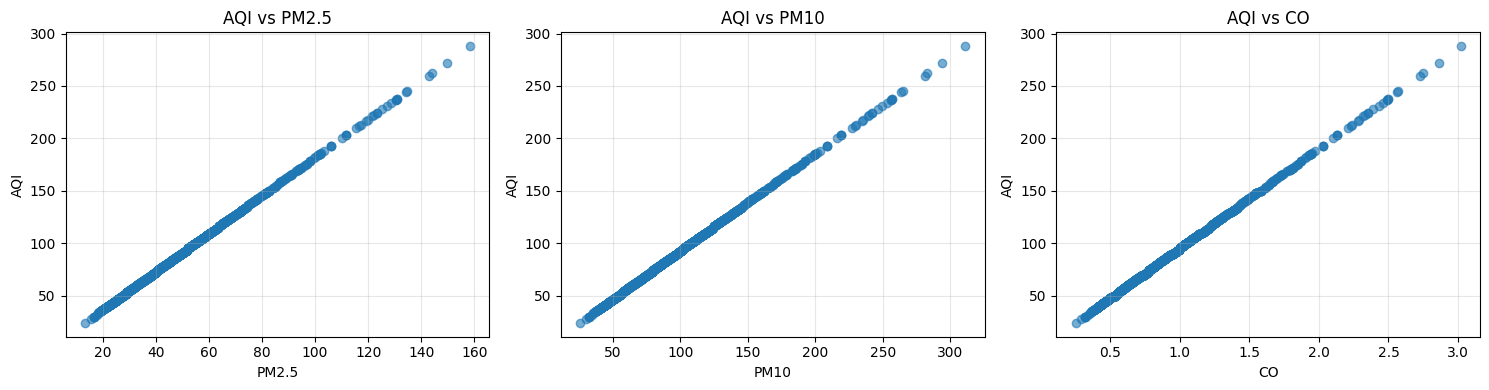

Cleaned data saved as City_Air_Quality_Cleaned.csv


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

url = (
    "https://raw.githubusercontent.com/cp099/"
    "India-Air-Quality-Dataset/main/Chennai_AQI_Dataset.csv"
)
df = pd.read_csv(url, encoding="utf-8-sig")


df.columns = df.columns.str.strip()

print("First rows:")
print(df.head())

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum())


df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d/%m/%y",
    errors="coerce"
)

pollutants = ["PM2.5", "PM10", "CO"]
measurements = ["AQI"] + [col for col in pollutants if col in df.columns]

for col in measurements:
    df[col] = pd.to_numeric(df[col], errors="coerce")


df = df.dropna(subset=["Date"]).sort_values("Date")

if "AQI" in df.columns:
    plt.figure(figsize=(11, 4))
    plt.plot(df["Date"], df["AQI"], marker=".", linewidth=1)
    plt.title("Chennai AQI Trend Over Time")
    plt.xlabel("Date")
    plt.ylabel("AQI")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


available_pollutants = [col for col in pollutants if col in df.columns]

if available_pollutants:
    fig, axes = plt.subplots(
        len(available_pollutants),
        1,
        figsize=(11, 3 * len(available_pollutants)),
        sharex=True
    )

    if len(available_pollutants) == 1:
        axes = [axes]

    for ax, col in zip(axes, available_pollutants):
        ax.plot(df["Date"], df[col], label=col, linewidth=1)
        ax.set_title(f"{col} Trend Over Time")
        ax.set_ylabel(col)
        ax.grid(True, alpha=0.3)
        ax.legend()

    axes[-1].set_xlabel("Date")
    plt.tight_layout()
    plt.show()


if "AQI" in df.columns:
    plt.figure(figsize=(8, 4))
    plt.hist(df["AQI"].dropna(), bins=20, edgecolor="black")
    plt.title("Distribution of Chennai AQI")
    plt.xlabel("AQI")
    plt.ylabel("Number of readings")
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


if "AQI" in df.columns and available_pollutants:
    fig, axes = plt.subplots(
        1,
        len(available_pollutants),
        figsize=(5 * len(available_pollutants), 4)
    )

    if len(available_pollutants) == 1:
        axes = [axes]

    for ax, col in zip(axes, available_pollutants):
        plot_data = df[[col, "AQI"]].dropna()
        ax.scatter(plot_data[col], plot_data["AQI"], alpha=0.6)
        ax.set_title(f"AQI vs {col}")
        ax.set_xlabel(col)
        ax.set_ylabel("AQI")
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


df.to_csv("City_Air_Quality_Cleaned.csv", index=False)
print("Cleaned data saved as City_Air_Quality_Cleaned.csv")
